In [ ]:
import os
import zipfile
import random
import shutil
import numpy as np
import tensorflow as tf
import matplotlib.pyplot as plt
import seaborn as sns
from tensorflow.keras import layers, models
from tensorflow.keras.optimizers import Adam
from tensorflow.keras.preprocessing.image import ImageDataGenerator
from tensorflow.keras.applications import EfficientNetB0
from tensorflow.keras.applications.efficientnet import preprocess_input
from sklearn.metrics import accuracy_score, f1_score, classification_report, confusion_matrix
from tensorflow.keras.callbacks import EarlyStopping, ModelCheckpoint
from tensorflow.keras.preprocessing import image

In [ ]:
# Set the random seeds for reproducibility
seed = 42
random.seed(seed)
np.random.seed(seed)
tf.random.set_seed(seed)

zip_file_path = "/content/Datasetplant.zip"  # your zip file
extraction_path = "/content/dataset"

# Make sure extraction folder exists
os.makedirs(extraction_path, exist_ok=True)

# Extract the zip (always extract to avoid skipping)
with zipfile.ZipFile(zip_file_path, 'r') as zip_ref:
    zip_ref.extractall(extraction_path)
print(f"Dataset extracted to {extraction_path}")

# Check what got extracted
extracted_files = os.listdir(extraction_path)
print("Files extracted:", extracted_files)

# Automatically detect the dataset folder (first folder inside extraction_path)
if len(extracted_files) == 1 and os.path.isdir(os.path.join(extraction_path, extracted_files[0])):
    dataset_dir = os.path.join(extraction_path, extracted_files[0])
else:
    dataset_dir = extraction_path  # fallback

# Detect classes (subfolders)
class_names = [d for d in os.listdir(dataset_dir) if os.path.isdir(os.path.join(dataset_dir, d))]
print("Classes detected:", class_names)


Dataset extracted to /content/dataset
Files extracted: ['tomato']
Classes detected: ['train', 'val']


In [ ]:
# 3. **Preprocess Dataset: Create Data Generators**
IMG_CNN = (150, 150)
IMG_RES = (224, 224)

train_datagen = ImageDataGenerator(
    rescale=1./255,
    rotation_range=30,
    width_shift_range=0.2,
    height_shift_range=0.2,
    shear_range=0.2,
    zoom_range=0.2,
    horizontal_flip=True,
    validation_split=0.2
)

val_datagen = ImageDataGenerator(
    rescale=1./255,
    validation_split=0.2
)

test_datagen = ImageDataGenerator(rescale=1./255)

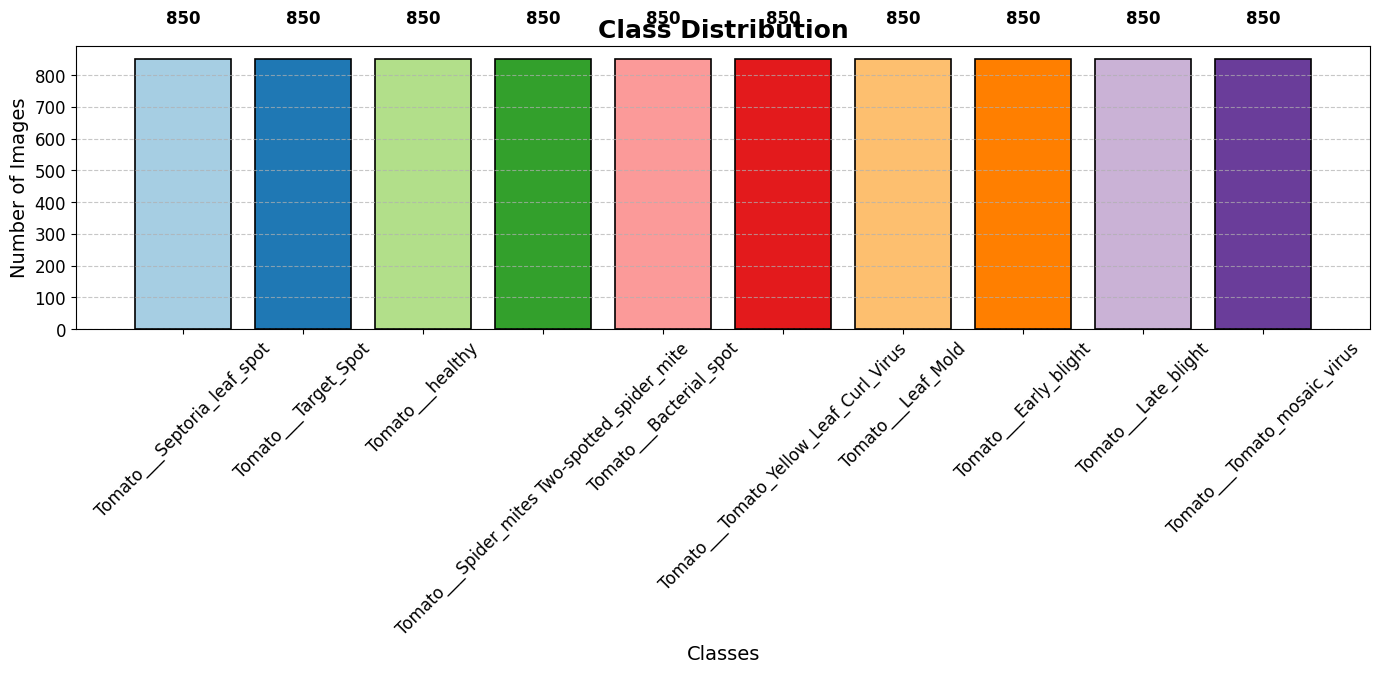

In [100]:
import os
import matplotlib.pyplot as plt
import numpy as np

def plot_class_distribution(dataset_dir):
    class_counts = {cls: len(os.listdir(os.path.join(dataset_dir, cls))) for cls in class_names}

    # Create the bar chart with custom colors
    plt.figure(figsize=(14, 7))
    bars = plt.bar(class_counts.keys(), class_counts.values(), color=plt.cm.Paired.colors[:len(class_counts)])

    # Add title and labels with improved fonts
    plt.title('Class Distribution', fontsize=18, fontweight='bold')
    plt.xlabel('Classes', fontsize=14)
    plt.ylabel('Number of Images', fontsize=14)
    plt.xticks(rotation=45, fontsize=12)
    plt.yticks(fontsize=12)

    # Add data labels on top of the bars with adjusted position
    for bar in bars:
        yval = bar.get_height()
        # Increase the vertical offset for labels (yval + 100 instead of yval + 50)
        plt.text(bar.get_x() + bar.get_width() / 2, yval + 100,  # Adjust position of text
                 f'{yval}', ha='center', va='bottom', fontweight='bold', fontsize=12)

    # Adding grid lines for clarity
    plt.grid(axis='y', linestyle='--', alpha=0.7)

    # Add bar edges for better distinction between bars
    for bar in bars:
        bar.set_edgecolor('black')
        bar.set_linewidth(1.2)

    # Tighten the layout to avoid clipping
    plt.tight_layout()

    # Show the plot
    plt.show()

# Run the function to plot the class distribution with data labels
plot_class_distribution(dataset_dir)


Processing class: Tomato___Septoria_leaf_spot
Processing class: Tomato___Target_Spot
Processing class: Tomato___healthy
Processing class: Tomato___Spider_mites Two-spotted_spider_mite
Processing class: Tomato___Bacterial_spot
Processing class: Tomato___Tomato_Yellow_Leaf_Curl_Virus
Processing class: Tomato___Leaf_Mold
Processing class: Tomato___Early_blight
Processing class: Tomato___Late_blight
Processing class: Tomato___Tomato_mosaic_virus


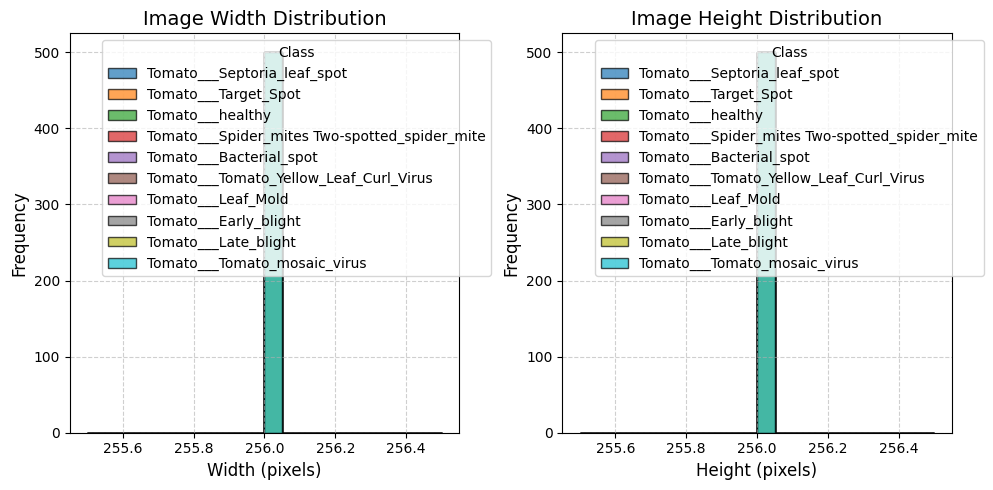

In [89]:
import os
import random
import shutil
import matplotlib.pyplot as plt
from PIL import Image

# Corrected dataset path
dataset_dir = "/content/dataset/tomato/train"  # Path to the "train" folder

# Function to collect image sizes (width and height), and an optional sample_max argument
def collect_image_sizes(folder, exts=(".jpg", ".jpeg", ".png", ".bmp", ".tif", ".tiff"), sample_max=None):
    sizes_w, sizes_h = [], []
    files = [f for f in os.listdir(folder) if f.lower().endswith(exts)]

    if len(files) == 0:
        print(f"No image files found in {folder}")

    if sample_max is not None:
        files = random.sample(files, min(sample_max, len(files)))  # Only sample if sample_max is provided

    for f in files:
        try:
            img_path = os.path.join(folder, f)
            with Image.open(img_path) as im:
                w, h = im.size
                sizes_w.append(w)
                sizes_h.append(h)
        except Exception as e:
            print(f"Error loading image {f}: {e}")

    return sizes_w, sizes_h

# Collect image sizes for each class (folder)
class_image_sizes = {}
for cls in os.listdir(dataset_dir):
    cls_folder = os.path.join(dataset_dir, cls)
    if os.path.isdir(cls_folder):  # Only process directories
        print(f"Processing class: {cls}")  # Debug: Print class name being processed
        w, h = collect_image_sizes(cls_folder, sample_max=500)  # Now it's correct
        if w:  # Only include classes with images
            class_image_sizes[cls] = (w, h)

# Check if any data was collected
if not class_image_sizes:
    print("No image size data collected. Please verify the dataset structure.")
else:
    # Plot the width and height distributions with improved aesthetics
    plt.figure(figsize=(10, 5))

    # Width distribution
    plt.subplot(1, 2, 1)
    for cls, (w, _) in class_image_sizes.items():
        plt.hist(w, bins=20, alpha=0.7, label=cls, edgecolor='black')  # Adding edgecolor for clarity
    plt.xlabel("Width (pixels)", fontsize=12)
    plt.ylabel("Frequency", fontsize=12)
    plt.title("Image Width Distribution", fontsize=14)
    plt.legend(title="Class", loc='upper right', bbox_to_anchor=(1.1, 1), fontsize=10)
    plt.grid(True, linestyle='--', alpha=0.6)

    # Height distribution
    plt.subplot(1, 2, 2)
    for cls, (_, h) in class_image_sizes.items():
        plt.hist(h, bins=20, alpha=0.7, label=cls, edgecolor='black')  # Adding edgecolor for clarity
    plt.xlabel("Height (pixels)", fontsize=12)
    plt.ylabel("Frequency", fontsize=12)
    plt.title("Image Height Distribution", fontsize=14)
    plt.legend(title="Class", loc='upper right', bbox_to_anchor=(1.1, 1), fontsize=10)
    plt.grid(True, linestyle='--', alpha=0.6)

    # Adjust layout to make room for the legend and labels
    plt.tight_layout()
    plt.show()


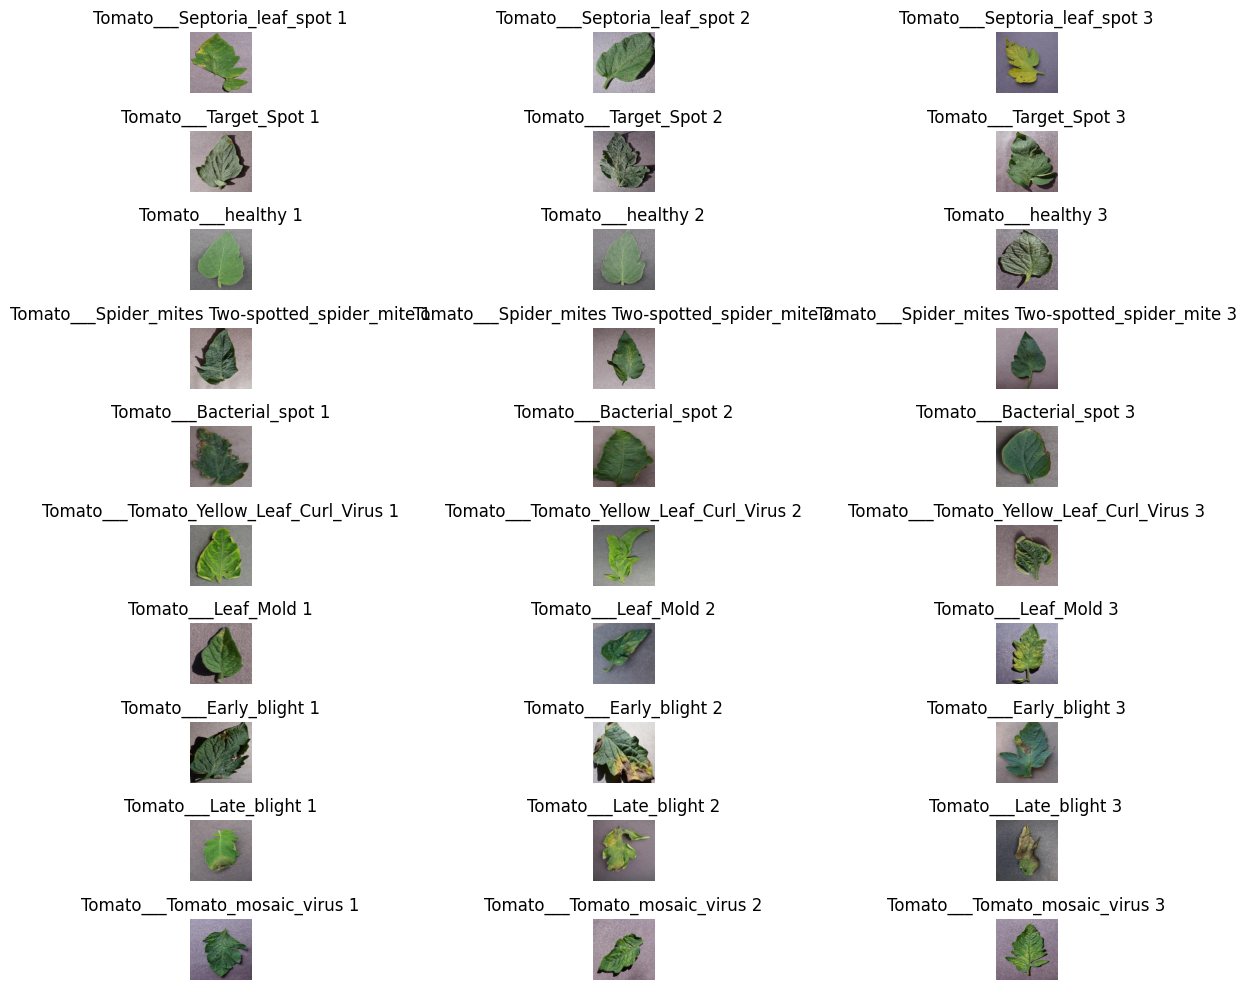

In [ ]:
import random
import matplotlib.pyplot as plt
import matplotlib.image as mpimg
import os

# Correct the dataset directory path
dataset_dir = "/content/dataset/tomato/train"  # Path to the "train" folder

# Get only subdirectories from dataset_dir (exclude any files or unwanted directories)
class_names = [folder for folder in os.listdir(dataset_dir) if os.path.isdir(os.path.join(dataset_dir, folder))]

# Function to plot random images from each class
def plot_random_images(dataset_dir, n=3):
    plt.figure(figsize=(15, 10))
    for i, cls in enumerate(class_names):
        class_folder = os.path.join(dataset_dir, cls)
        img_files = random.sample(os.listdir(class_folder), n)
        for j, img_file in enumerate(img_files):
            img_path = os.path.join(class_folder, img_file)
            img = mpimg.imread(img_path)
            plt.subplot(len(class_names), n, i * n + j + 1)
            plt.imshow(img)
            plt.axis('off')
            plt.title(f"{cls} {j + 1}")
    plt.tight_layout()
    plt.show()

# Display random sample images from each class
plot_random_images(dataset_dir, n=3)  # 3 random images per class


In [ ]:
# Parameters
test_fraction = 0.15  # 15% of data for test
test_root = "/content/dataset/Test"

# Create test folders
os.makedirs(test_root, exist_ok=True)

for cls in class_names:
    src = os.path.join(dataset_dir, cls)
    dst = os.path.join(test_root, cls)
    os.makedirs(dst, exist_ok=True)

    # List all images in class folder
    files = [f for f in os.listdir(src) if f.lower().endswith((".jpg", ".jpeg", ".png", ".bmp", ".tif", ".tiff"))]
    random.shuffle(files)

    n_test = max(1, int(len(files) * test_fraction))

    # Move test images to test folder
    for f in files[:n_test]:
        shutil.move(os.path.join(src, f), os.path.join(dst, f))

print("Test split created successfully.")

Test split created successfully.


In [ ]:
# 5. **Train-Test Split (For simplicity, we do it dynamically using ImageDataGenerator)**

# Train and validation generators for CNN
train_generator_cnn = train_datagen.flow_from_directory(
    dataset_dir,
    target_size=IMG_CNN,
    batch_size=32,
    class_mode='categorical',  # For multi-class classification
    subset='training',
    shuffle=True, seed=seed
)

validation_generator_cnn = val_datagen.flow_from_directory(
    dataset_dir,
    target_size=IMG_CNN,
    batch_size=32,
    class_mode='categorical',  # For multi-class classification
    subset='validation',
    shuffle=False, seed=seed
)

# Test generator (no augmentation)
test_generator = test_datagen.flow_from_directory(
    "/content/dataset/Test",  # Assuming test set is in a separate folder
    target_size=IMG_CNN,
    batch_size=32,
    class_mode='categorical',  # For multi-class classification
    shuffle=False
)


Found 6800 images belonging to 10 classes.
Found 1700 images belonging to 10 classes.
Found 1500 images belonging to 10 classes.


In [ ]:
# 6. **Train CNN Model**
num_classes = len(class_names)

model_cnn = models.Sequential([
    layers.Conv2D(32, (3,3), activation='relu', input_shape=(IMG_CNN[0], IMG_CNN[1], 3)),
    layers.MaxPooling2D(2,2),
    layers.Conv2D(64, (3,3), activation='relu'),
    layers.MaxPooling2D(2,2),
    layers.Conv2D(128, (3,3), activation='relu'),
    layers.MaxPooling2D(2,2),
    layers.Flatten(),
    layers.Dense(512, activation='relu'),
    layers.Dropout(0.5),
    layers.Dense(num_classes, activation='softmax')  # For multi-class classification
])

model_cnn.compile(optimizer=Adam(1e-3), loss='categorical_crossentropy', metrics=['accuracy'])


# Callbacks to ensure 5 epochs minimum
ck_cnn = ModelCheckpoint("best_cnn.h5", monitor='val_accuracy', save_best_only=True)
es_cnn = EarlyStopping(monitor='val_loss', patience=3, restore_best_weights=True)

history_cnn = model_cnn.fit(
    train_generator_cnn,
    epochs=5,  # Ensure it runs for at least 5 epochs
    validation_data=validation_generator_cnn,
    callbacks=[ck_cnn, es_cnn]
)

/usr/local/lib/python3.12/dist-packages/keras/src/layers/convolutional/base_conv.py:113: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)
/usr/local/lib/python3.12/dist-packages/keras/src/trainers/data_adapters/py_dataset_adapter.py:121: UserWarning: Your `PyDataset` class should call `super().__init__(**kwargs)` in its constructor. `**kwargs` can include `workers`, `use_multiprocessing`, `max_queue_size`. Do not pass these arguments to `fit()`, as they will be ignored.
  self._warn_if_super_not_called()


Epoch 1/5
213/213 ━━━━━━━━━━━━━━━━━━━━ 0s 1s/step - accuracy: 0.2500 - loss: 2.0694

213/213 ━━━━━━━━━━━━━━━━━━━━ 297s 1s/step - accuracy: 0.2505 - loss: 2.0679 - val_accuracy: 0.5388 - val_loss: 1.3969
Epoch 2/5
213/213 ━━━━━━━━━━━━━━━━━━━━ 303s 1s/step - accuracy: 0.5933 - loss: 1.1485 - val_accuracy: 0.4741 - val_loss: 1.7938
Epoch 3/5
213/213 ━━━━━━━━━━━━━━━━━━━━ 0s 1s/step - accuracy: 0.6738 - loss: 0.9234

213/213 ━━━━━━━━━━━━━━━━━━━━ 295s 1s/step - accuracy: 0.6738 - loss: 0.9234 - val_accuracy: 0.7106 - val_loss: 0.8287
Epoch 4/5
213/213 ━━━━━━━━━━━━━━━━━━━━ 276s 1s/step - accuracy: 0.7268 - loss: 0.7855 - val_accuracy: 0.6512 - val_loss: 1.0261
Epoch 5/5
213/213 ━━━━━━━━━━━━━━━━━━━━ 285s 1s/step - accuracy: 0.7616 - loss: 0.6768 - val_accuracy: 0.6694 - val_loss: 0.9635


In [ ]:
model_cnn.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 148, 148, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 74, 74, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 72, 72, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 36, 36, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 34, 34, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 17, 17, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 36992)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 512)            │    18,940,416 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 512)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 10)             │         5,130 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 57,116,384 (217.88 MB)

 Trainable params: 19,038,794 (72.63 MB)

 Non-trainable params: 0 (0.00 B)

 Optimizer params: 38,077,590 (145.25 MB)

=== CNN (TEST) ===
Accuracy: 0.7273333333333334
Macro F1: 0.7270099497146042
                                               precision    recall  f1-score   support

                  Tomato___Septoria_leaf_spot       0.93      0.74      0.82       150
                         Tomato___Target_Spot       0.66      0.57      0.61       150
                             Tomato___healthy       0.73      0.63      0.67       150
Tomato___Spider_mites Two-spotted_spider_mite       0.92      0.68      0.78       150
                      Tomato___Bacterial_spot       0.70      0.57      0.62       150
       Tomato___Tomato_Yellow_Leaf_Curl_Virus       0.56      0.67      0.61       150
                           Tomato___Leaf_Mold       0.57      0.71      0.63       150
                        Tomato___Early_blight       0.76      0.88      0.82       150
                         Tomato___Late_blight       0.91      0.83      0.87       150
                 Tomato___Tomato_mosaic_virus       

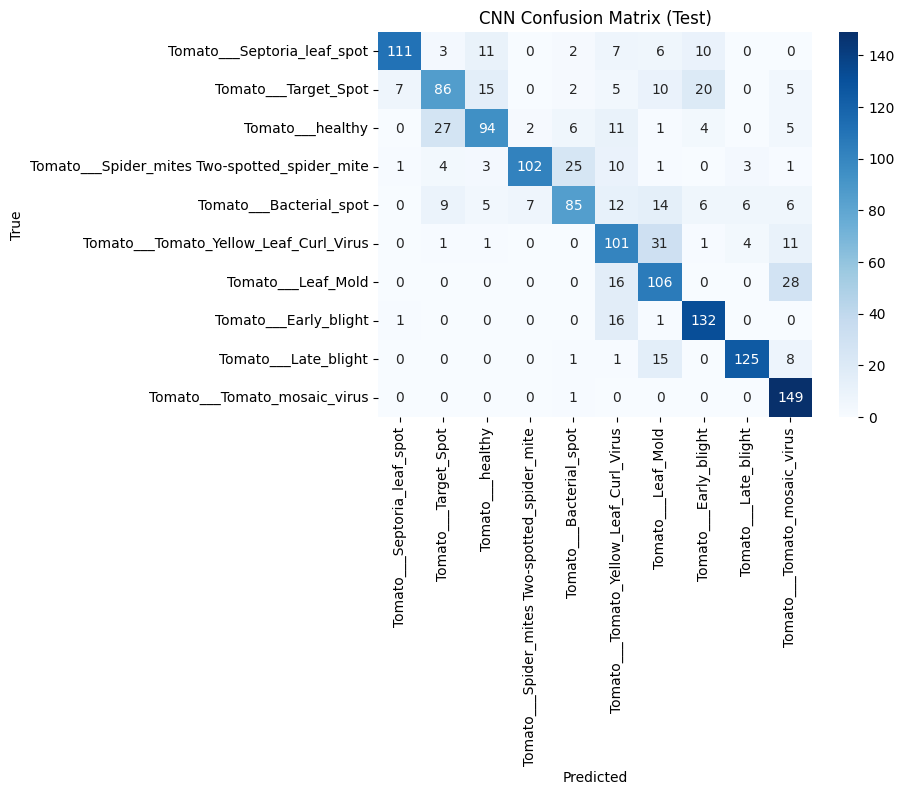

In [ ]:
# CNN Evaluation
y_true_cnn = test_generator.classes
y_prob_cnn = model_cnn.predict(test_generator, verbose=0)
y_pred_cnn = np.argmax(y_prob_cnn, axis=1)

print("=== CNN (TEST) ===")
print("Accuracy:", accuracy_score(y_true_cnn, y_pred_cnn))
print("Macro F1:", f1_score(y_true_cnn, y_pred_cnn, average='macro'))
print(classification_report(y_true_cnn, y_pred_cnn, target_names=class_names))

# Confusion Matrix for CNN
cm_cnn = confusion_matrix(y_true_cnn, y_pred_cnn)
plt.figure(figsize=(7,5))
sns.heatmap(cm_cnn, annot=True, fmt='d', cmap='Blues',
            xticklabels=class_names,
            yticklabels=class_names)
plt.title('CNN Confusion Matrix (Test)')
plt.xlabel('Predicted'); plt.ylabel('True')
plt.show()




In [ ]:
# 7. **Create DNN Model**
model_dnn = models.Sequential([
    layers.Flatten(input_shape=(224, 224, 3)),  # Flatten the input image (matching the input shape of 224x224x3)
    layers.Dense(512, activation='relu'),  # Fully connected layer
    layers.Dropout(0.5),  # Dropout layer for regularization
    layers.Dense(256, activation='relu'),  # Another fully connected layer
    layers.Dense(num_classes, activation='softmax')  # Output layer for multi-class classification
])

# Compile the DNN model
model_dnn.compile(optimizer=Adam(1e-3), loss='categorical_crossentropy', metrics=['accuracy'])

# Callbacks (Model Checkpoint to save the best model)
ck_dnn = ModelCheckpoint("best_dnn.h5", monitor='val_accuracy', save_best_only=True)

# Train the DNN model (ensuring 5 epochs)
history_dnn = model_dnn.fit(
    train_generator_cnn,
    epochs=5,  # Train exactly 5 epochs
    validation_data=validation_generator_cnn,
    callbacks=[ck_dnn]
)


Epoch 1/5
213/213 ━━━━━━━━━━━━━━━━━━━━ 0s 2s/step - accuracy: 0.0992 - loss: 14.1794

213/213 ━━━━━━━━━━━━━━━━━━━━ 400s 2s/step - accuracy: 0.0992 - loss: 14.1807 - val_accuracy: 0.1000 - val_loss: 14.5063
Epoch 2/5
213/213 ━━━━━━━━━━━━━━━━━━━━ 400s 2s/step - accuracy: 0.0989 - loss: 14.5247 - val_accuracy: 0.1000 - val_loss: 14.5063
Epoch 3/5
213/213 ━━━━━━━━━━━━━━━━━━━━ 398s 2s/step - accuracy: 0.0999 - loss: 14.5085 - val_accuracy: 0.1000 - val_loss: 14.5063
Epoch 4/5
213/213 ━━━━━━━━━━━━━━━━━━━━ 384s 2s/step - accuracy: 0.0946 - loss: 14.5937 - val_accuracy: 0.1000 - val_loss: 14.5063
Epoch 5/5
213/213 ━━━━━━━━━━━━━━━━━━━━ 398s 2s/step - accuracy: 0.0978 - loss: 14.5418 - val_accuracy: 0.1000 - val_loss: 14.5063


In [ ]:
model_dnn.summary()

Model: "sequential_10"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ flatten_2 (Flatten)             │ (None, 150528)         │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_13 (Dense)                │ (None, 512)            │    77,070,848 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_10 (Dropout)            │ (None, 512)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_14 (Dense)                │ (None, 256)            │       131,328 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_15 (Dense)                │ (None, 10)             │         2,570 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 231,614,244 (883.54 MB)

 Trainable params: 77,204,746 (294.51 MB)

 Non-trainable params: 0 (0.00 B)

 Optimizer params: 154,409,498 (589.03 MB)

=== DNN (TEST) ===
Accuracy: 0.1
Precision: 0.01
Recall: 0.1
F1 Score: 0.01818181818181818
                                               precision    recall  f1-score   support

                  Tomato___Septoria_leaf_spot       0.00      0.00      0.00       150
                         Tomato___Target_Spot       0.00      0.00      0.00       150
                             Tomato___healthy       0.00      0.00      0.00       150
Tomato___Spider_mites Two-spotted_spider_mite       0.00      0.00      0.00       150
                      Tomato___Bacterial_spot       0.00      0.00      0.00       150
       Tomato___Tomato_Yellow_Leaf_Curl_Virus       0.10      1.00      0.18       150
                           Tomato___Leaf_Mold       0.00      0.00      0.00       150
                        Tomato___Early_blight       0.00      0.00      0.00       150
                         Tomato___Late_blight       0.00      0.00      0.00       150
                 Tomato___Tomato_mosai

/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.12/dist-packages/sklearn/m

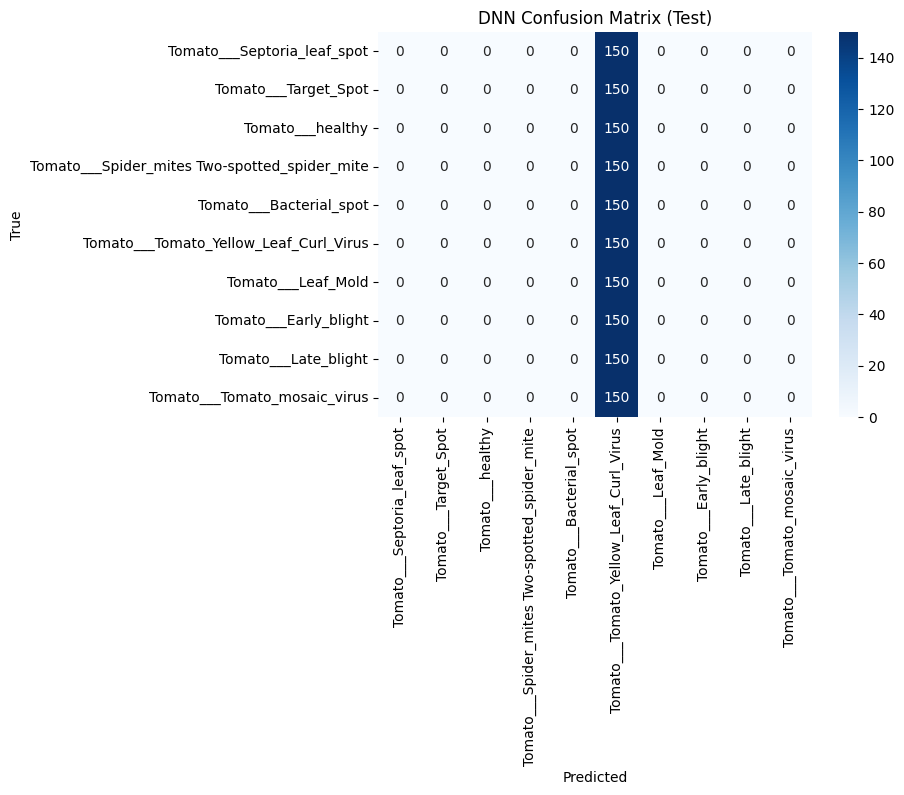

In [ ]:
from sklearn.metrics import precision_score, recall_score, f1_score, accuracy_score, classification_report, confusion_matrix
# 8. **Evaluate DNN Model**: Get the predictions and calculate metrics
y_true_dnn = test_generator.classes
y_prob_dnn = model_dnn.predict(test_generator, verbose=0)
y_pred_dnn = np.argmax(y_prob_dnn, axis=1)

# 9. **Accuracy, Precision, Recall, and F1-Score for DNN**
print("=== DNN (TEST) ===")
print("Accuracy:", accuracy_score(y_true_dnn, y_pred_dnn))
print("Precision:", precision_score(y_true_dnn, y_pred_dnn, average='macro'))
print("Recall:", recall_score(y_true_dnn, y_pred_dnn, average='macro'))
print("F1 Score:", f1_score(y_true_dnn, y_pred_dnn, average='macro'))
print(classification_report(y_true_dnn, y_pred_dnn, target_names=class_names))

# 10. **Confusion Matrix for DNN**
cm_dnn = confusion_matrix(y_true_dnn, y_pred_dnn)
plt.figure(figsize=(7,5))
sns.heatmap(cm_dnn, annot=True, fmt='d', cmap='Blues',
            xticklabels=class_names,
            yticklabels=class_names)
plt.title('DNN Confusion Matrix (Test)')
plt.xlabel('Predicted'); plt.ylabel('True')
plt.show()

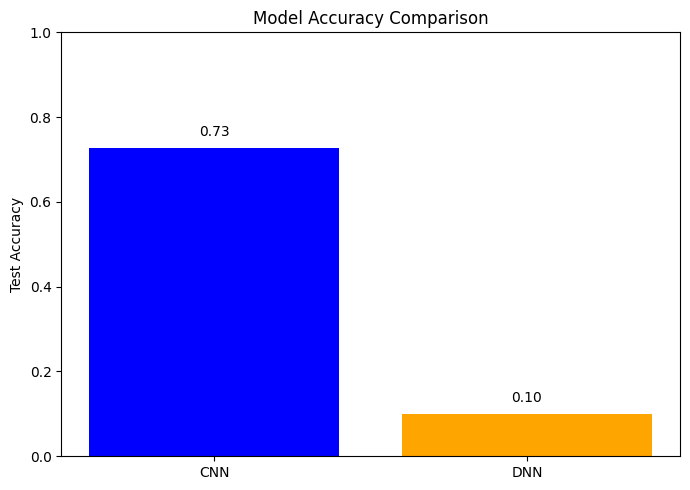

In [ ]:
import matplotlib.pyplot as plt
from sklearn.metrics import accuracy_score

# Get accuracy for CNN and DNN
acc_cnn = accuracy_score(y_true_cnn, y_pred_cnn)
acc_dnn = accuracy_score(y_true_dnn, y_pred_dnn)

# Bar plot for model comparison
plt.figure(figsize=(7,5))
bars = plt.bar(['CNN', 'DNN'], [acc_cnn, acc_dnn], color=['blue', 'orange'])
plt.ylim(0, 1)  # Accuracy is between 0 and 1
plt.ylabel('Test Accuracy')
plt.title('Model Accuracy Comparison')

# Adding the accuracy values on top of the bars
for b in bars:
    y = b.get_height()
    plt.text(b.get_x() + b.get_width()/2, y + 0.02, f"{y:.2f}", ha='center', va='bottom')

plt.tight_layout()
plt.show()


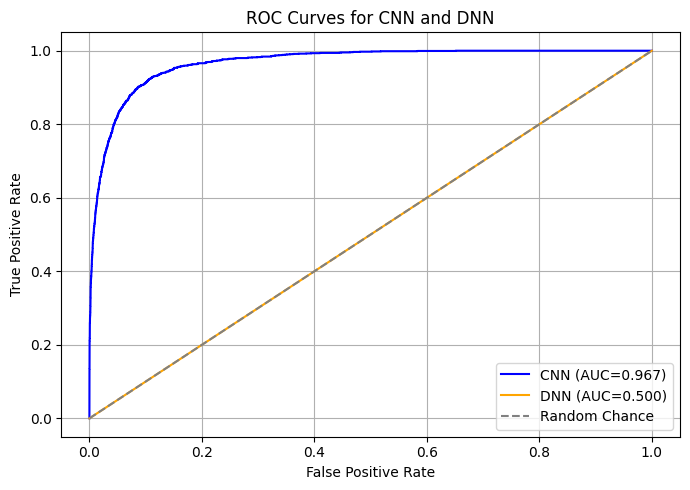

In [ ]:
from sklearn.preprocessing import LabelBinarizer
from sklearn.metrics import roc_curve, auc
import matplotlib.pyplot as plt
import numpy as np

# 2. **ROC Curves for CNN and DNN**
# Binarize the labels for multi-class ROC AUC curve
lb = LabelBinarizer()
y_true_binarized = lb.fit_transform(y_true_cnn)  # Binarize y_true for CNN

# CNN ROC Curve
fpr_cnn, tpr_cnn, _ = roc_curve(y_true_binarized.ravel(), y_prob_cnn.ravel())  # Flatten and calculate ROC curve
auc_cnn = auc(fpr_cnn, tpr_cnn)

# DNN ROC Curve
y_true_dnn_binarized = lb.transform(y_true_dnn)  # Binarize y_true for DNN
fpr_dnn, tpr_dnn, _ = roc_curve(y_true_dnn_binarized.ravel(), y_prob_dnn.ravel())  # Flatten and calculate ROC curve
auc_dnn = auc(fpr_dnn, tpr_dnn)

# Plot the ROC curves
plt.figure(figsize=(7,5))
plt.plot(fpr_cnn, tpr_cnn, label=f'CNN (AUC={auc_cnn:.3f})', color='blue')
plt.plot(fpr_dnn, tpr_dnn, label=f'DNN (AUC={auc_dnn:.3f})', color='orange')
plt.plot([0, 1], [0, 1], linestyle='--', label='Random Chance', color='grey')

# Add labels and legends
plt.title('ROC Curves for CNN and DNN')
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.legend(loc='lower right')
plt.grid(True)
plt.tight_layout()
plt.show()


1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 47ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 50ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 44ms/step


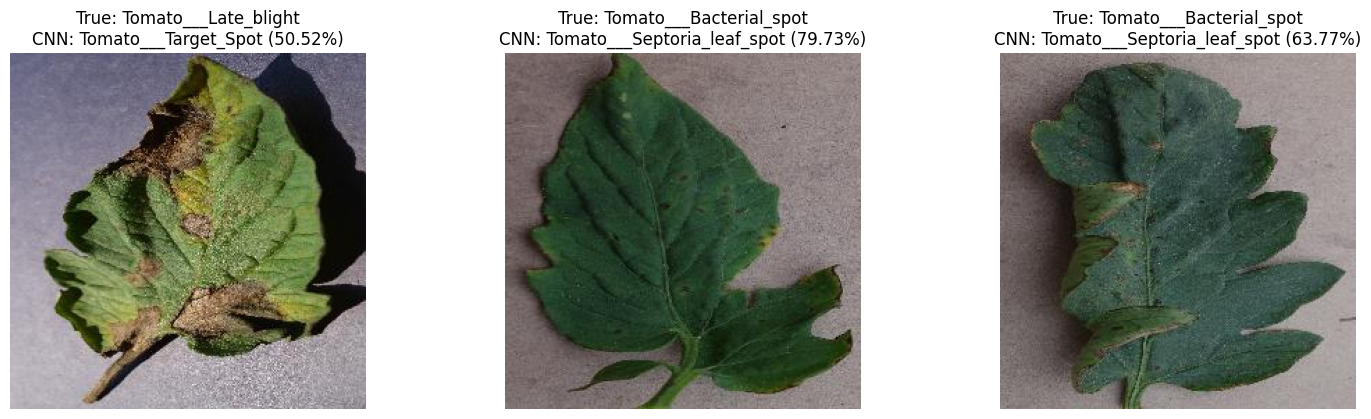

In [ ]:
import random
import matplotlib.pyplot as plt
import matplotlib.image as mpimg
import numpy as np
from tensorflow.keras.preprocessing import image

# Function to predict using CNN model
def predict_with_cnn(model_cnn, img_path):
    img = image.load_img(img_path, target_size=IMG_CNN)  # Resize for CNN model (150x150)
    img_array_cnn = image.img_to_array(img) / 255.0  # Normalize the image
    img_array_cnn = np.expand_dims(img_array_cnn, axis=0)  # Add batch dimension
    cnn_pred_prob = model_cnn.predict(img_array_cnn)
    cnn_pred_class = np.argmax(cnn_pred_prob)
    cnn_pred_score = cnn_pred_prob[0][cnn_pred_class]
    return cnn_pred_class, cnn_pred_score

# Function to predict and display results for a few random images using CNN only
def predict_and_display_images_cnn(model_cnn, test_generator, n=3):
    # Pick random 6 images from the test set
    test_images = random.sample(range(len(test_generator.filenames)), n)

    # Prepare figure to display images and predictions
    plt.figure(figsize=(15, 8))

    for i, idx in enumerate(test_images):
        # Get the image path and load the image
        img_path = os.path.join(test_generator.directory, test_generator.filenames[idx])
        img = mpimg.imread(img_path)

        # Get the true class from the image filename
        true_class = test_generator.filenames[idx].split('/')[0]  # Extract class from filename

        # Predict with CNN
        cnn_pred_class, cnn_pred_score = predict_with_cnn(model_cnn, img_path)

        # Display image
        plt.subplot(2, 3, i + 1)
        plt.imshow(img)
        plt.axis('off')
        plt.title(f"True: {true_class}\nCNN: {class_names[cnn_pred_class]} ({cnn_pred_score*100:.2f}%)")

    plt.tight_layout()
    plt.show()

# Run the function for 6 random predictions using CNN only
predict_and_display_images_cnn(model_cnn, test_generator, n=3)
